# Health Study – Part 1: Descriptive Analysis and Statistics

## Introduction
In this notebook I analyse data from a health study with 800 participants.
The dataset contains age, sex, height, weight, systolic blood pressure,
cholesterol, smoking habits and whether the person has a certain disease.

The goals of Part 1 are to:
1. Describe the data with basic statistics and graphs.
2. Simulate the disease rate with numpy and compare it with the real data.
3. Calculate a confidence interval for the mean systolic blood pressure.
4. Test if smokers have higher blood pressure than non-smokers.
5. Check how good the test is with a power simulation.

## 1. Setup
I import the libraries, set a random seed so that all simulations give
the same result every time, and load the data with a relative path.

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

# Seed 42 as required, so random results are the same every time
np.random.seed(42)

# Read the data with a relative path
df = pd.read_csv("data/health_study_dataset.csv")

df.head()

,id,age,sex,height,weight,systolic_bp,cholesterol,smoker,disease
0,1,57,F,168.9,65.8,141.8,4.58,No,0
1,2,47,M,180.4,95.9,144.8,5.18,Yes,0
2,3,59,F,169.9,82.2,151.7,6.16,No,0
3,4,72,M,157.7,93.1,151.0,6.63,No,0
4,5,46,M,192.6,104.1,144.1,5.21,No,0


## 2. Data quality check
Before the analysis I check the size of the data, the data types,
missing values and duplicates. Bad data gives bad results,
so this step is important.

In [2]:
# Size of the data (rows, columns)
print("Shape:", df.shape)

# Data type of each column
df.info()

# Count missing values in each column
print("\nMissing values per column:")
print(df.isnull().sum())

# Count duplicate rows (without id, because id is always unique)
print("\nDuplicate rows:", df.drop(columns="id").duplicated().sum())

Shape: (800, 9)
<class 'pandas.DataFrame'>
RangeIndex: 800 entries, 0 to 799
Data columns (total 9 columns):
 #   Column       Non-Null Count  Dtype  
---  ------       --------------  -----  
 0   id           800 non-null    int64  
 1   age          800 non-null    int64  
 2   sex          800 non-null    str    
 3   height       800 non-null    float64
 4   weight       800 non-null    float64
 5   systolic_bp  800 non-null    float64
 6   cholesterol  800 non-null    float64
 7   smoker       800 non-null    str    
 8   disease      800 non-null    int64  
dtypes: float64(4), int64(3), str(2)
memory usage: 56.4 KB

Missing values per column:
id             0
age            0
sex            0
height         0
weight         0
systolic_bp    0
cholesterol    0
smoker         0
disease        0
dtype: int64

Duplicate rows: 0


### Check for unusual values
Weight alone does not show if a value is strange, because it depends
on height. Therefore I calculate BMI and look at the lowest values.

In [3]:
# Range of all numeric columns
df.drop(columns="id").describe().round(2)

,age,height,weight,systolic_bp,cholesterol,disease
count,800.00,800.00,800.00,800.00,800.00,800.00
mean,49.43,171.85,73.41,149.18,4.93,0.06
std,14.50,9.80,13.69,12.79,0.85,0.24
min,18.00,144.40,33.70,106.80,2.50,0.00
25%,39.00,164.78,64.80,140.90,4.33,0.00
50%,50.00,171.35,73.20,149.40,4.97,0.00
75%,59.00,178.92,82.60,157.60,5.48,0.00
max,90.00,200.40,114.40,185.90,7.88,1.00


In [4]:
# BMI = weight (kg) / height (m)^2, to check if weight makes sense for the height
bmi = df["weight"] / (df["height"] / 100) ** 2

# The 5 people with the lowest BMI, with BMI in the same table
low_bmi = df.loc[bmi.nsmallest(5).index, ["age", "sex", "height", "weight"]]
low_bmi["bmi"] = bmi.round(1)
print(low_bmi)

# Count people with BMI under 16 (WHO: markedly increased health risk)
print("\nPeople with BMI < 16:", (bmi < 16).sum())

     age sex  height  weight   bmi
535   50   F   163.8    33.9  12.6
249   56   M   184.5    44.1  13.0
756   57   M   185.0    44.8  13.1
23    28   F   170.2    38.1  13.2
783   59   M   189.3    48.8  13.6

People with BMI < 16: 23


### Findings
- The data has 800 rows and 9 columns. There are no missing values
  and no duplicates, and all columns have the correct data types.
- I calculated BMI to check if weight and height make sense together.
  The lowest BMI is 12.6 (woman, 50 years, 163.8 cm, 33.9 kg).
  23 people have a BMI under 16, which WHO describes as a limit
  for markedly increased health risk.
- These values are unusual but possible, and I cannot prove that they
  are errors. Therefore I keep all rows in the analysis.

## 3. Descriptive statistics
I calculate the mean, median, min and max for the five numeric columns.
The mean shows the average value, and the median shows the middle value.
If they are close, the data is not very skewed.

In [5]:
# Columns from the assignment
num_cols = ["age", "weight", "height", "systolic_bp", "cholesterol"]

# Calculate all 4 values at once, .T flips the table so each column becomes a row
summary = df[num_cols].agg(["mean", "median", "min", "max"]).T
summary.round(2)

,mean,median,min,max
age,49.43,50.00,18.0,90.00
weight,73.41,73.20,33.7,114.40
height,171.85,171.35,144.4,200.40
systolic_bp,149.18,149.40,106.8,185.90
cholesterol,4.93,4.97,2.5,7.88


**Comment:** The mean and median are almost the same for all columns.
The average participant is about 49 years old. The mean systolic blood
pressure is 149 mmHg, which is above the common limit for high blood
pressure (140 mmHg). In section 4.1 I check how many participants
are above this limit.

## 4. Visualisation
### 4.1 Distribution of systolic blood pressure
A histogram shows how the values are spread. I add a line for the mean
and a line for 140 mmHg (limit for high blood pressure).

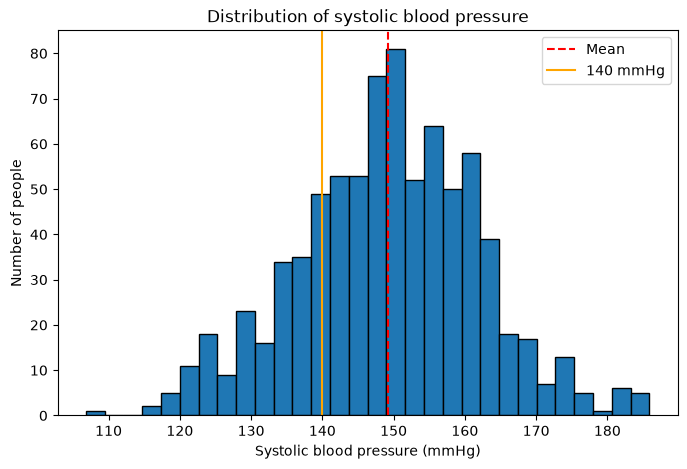

Share above 140 mmHg: 76.9%


In [6]:
fig, ax = plt.subplots(figsize=(8, 5))

# Histogram with 30 bins, black edges to see each bar clearly
ax.hist(df["systolic_bp"], bins=30, edgecolor="black")

# Red dashed line = mean
ax.axvline(df["systolic_bp"].mean(), color="red", linestyle="--", label="Mean")
# Orange line = limit for high blood pressure
ax.axvline(140, color="orange", label="140 mmHg")

ax.set_title("Distribution of systolic blood pressure")
ax.set_xlabel("Systolic blood pressure (mmHg)")
ax.set_ylabel("Number of people")
ax.legend()
plt.show()

# Share of people above 140 mmHg
above_140 = (df["systolic_bp"] > 140).mean() * 100
print(f"Share above 140 mmHg: {above_140:.1f}%")

**Comment:** The distribution looks like a bell curve (close to normal).
76.9% of the participants have a systolic blood pressure above 140 mmHg.

### 4.2 Weight by sex
A boxplot shows the median, the spread and possible outliers.
It is a good way to compare two groups.

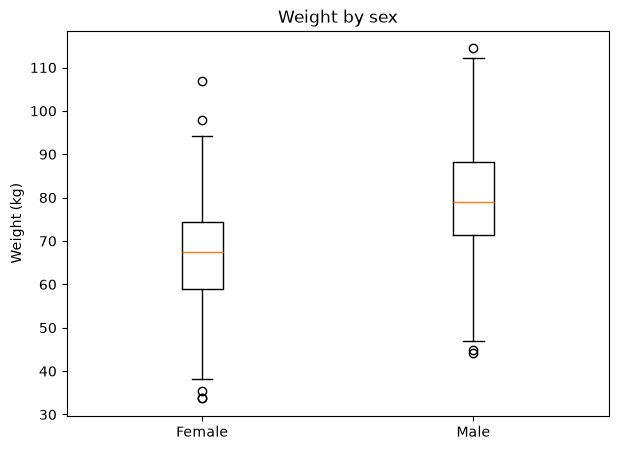

In [7]:
# Split weight into two groups by sex
weight_f = df[df["sex"] == "F"]["weight"]
weight_m = df[df["sex"] == "M"]["weight"]

fig, ax = plt.subplots(figsize=(7, 5))
ax.boxplot([weight_f, weight_m], tick_labels=["Female", "Male"])

ax.set_title("Weight by sex")
ax.set_ylabel("Weight (kg)")
plt.show()

**Comment:** Men are heavier than women. The median weight is about
79 kg for men and 67 kg for women. Both groups have some outliers,
both low and high. The three lowest points in the female group (33.7–35.5 kg) all have
a BMI under 16, so they are part of the 23 people I found in the
data quality check.

### 4.3 Share of smokers
I use a bar chart with percentages, because percentages are easier
to understand than counts.

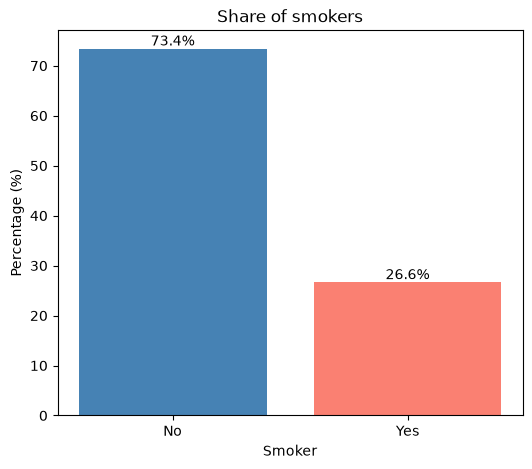

In [8]:
# normalize=True gives shares (0-1), times 100 gives percent
smoker_share = df["smoker"].value_counts(normalize=True) * 100

fig, ax = plt.subplots(figsize=(6, 5))
bars = ax.bar(smoker_share.index, smoker_share.values, color=["steelblue", "salmon"])

# Show the percent on top of each bar
ax.bar_label(bars, fmt="%.1f%%")

ax.set_title("Share of smokers")
ax.set_xlabel("Smoker")
ax.set_ylabel("Percentage (%)")
plt.show()

**Comment:** About 27% of the participants smoke and 73% do not smoke.
The smoker group is smaller, which is important to remember in the
hypothesis test later.

## 5. Simulation of disease
First I calculate the real share of people with the disease.
Then I use numpy to simulate 1000 random people with the same
probability, and compare the simulated share with the real share.

In [9]:
# disease is 0/1, so the mean is the share of people with the disease
p_real = df["disease"].mean()
n_sick = df["disease"].sum()

print(f"Real: {n_sick} of {len(df)} people have the disease ({p_real * 100:.2f}%)")

Real: 47 of 800 people have the disease (5.88%)


In [10]:
# Simulate 1000 people, each has the probability p_real to be sick (1 = sick, 0 = not sick)
simulated = np.random.binomial(n=1, p=p_real, size=1000)
p_sim = simulated.mean()

print(f"Simulated: {simulated.sum()} of 1000 people have the disease ({p_sim * 100:.2f}%)")
print(f"Difference: {(p_sim - p_real) * 100:.2f} percentage points")

Simulated: 56 of 1000 people have the disease (5.60%)
Difference: -0.27 percentage points


**Comment:** The real share is 5.88% (47 of 800). The simulated share
is 5.60% (56 of 1000). The difference is only 0.27 percentage points.
The simulation is not exactly the same as the real data, because
random samples always vary a little. This is called sampling variation.

### 5.1 Repeating the simulation
One simulation does not show how much the result can vary.
Therefore I repeat the simulation of 1000 people 10,000 times
and look at the distribution of the simulated shares.

95% of the simulations are between 4.5% and 7.4%


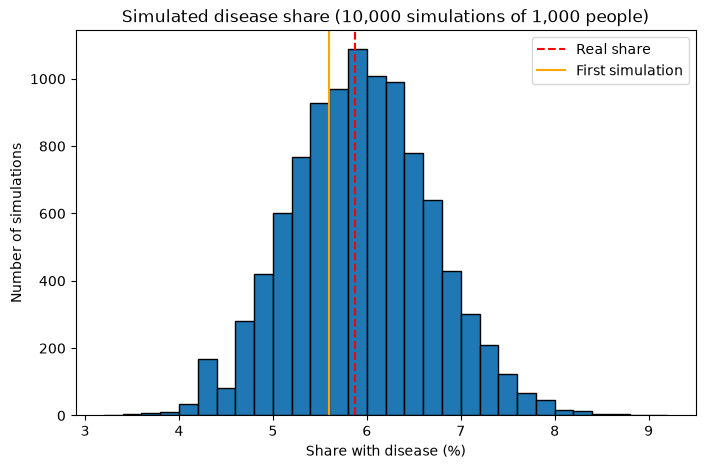

In [11]:
n_round = 10000

# Each round: simulate 1000 people, count the sick ones and divide by 1000 to get the share
sim_shares = np.random.binomial(n=1000, p=p_real, size=n_round) / 1000

# Range where 95% of the simulations are (cut 2.5% at each end)
low, high = np.percentile(sim_shares, [2.5, 97.5])
print(f"95% of the simulations are between {low * 100:.1f}% and {high * 100:.1f}%")

fig, ax = plt.subplots(figsize=(8, 5))
ax.hist(sim_shares * 100, bins=30, edgecolor="black")

# Red line = real share, orange line = first simulation from the cell above
ax.axvline(p_real * 100, color="red", linestyle="--", label="Real share")
ax.axvline(p_sim * 100, color="orange", label="First simulation")

ax.set_title("Simulated disease share (10,000 simulations of 1,000 people)")
ax.set_xlabel("Share with disease (%)")
ax.set_ylabel("Number of simulations")
ax.legend()
plt.show()

**Comment:** 95% of the simulations give a share between 4.5% and 7.4%.
My first simulation (5.60%) is well inside this range, so the
difference from the real share is normal random variation.
It also shows that with a rare disease and only 1000 people,
the simulated share can easily vary by about ±1.5 percentage points.

## 6. Confidence interval for mean systolic blood pressure
### 6.1 Normal approximation
The formula is: mean ± 1.96 × (std / √n).
I can use it because the sample is large (n = 800), so the mean
is approximately normally distributed (Central Limit Theorem).

In [12]:
bp = df["systolic_bp"]
n = len(bp)

mean_bp = bp.mean()
std_bp = bp.std()

# Standard error = how much the mean can vary
se = std_bp / np.sqrt(n)

# 1.96 covers 95% of a normal distribution
ci_low = mean_bp - 1.96 * se
ci_high = mean_bp + 1.96 * se

print(f"Mean: {mean_bp:.2f} mmHg")
print(f"95% CI (normal): [{ci_low:.2f} - {ci_high:.2f}] mmHg")

Mean: 149.18 mmHg
95% CI (normal): [148.29 - 150.07] mmHg


**Comment:** The 95% confidence interval is 148.29–150.07 mmHg.
This means that the true mean systolic blood pressure in the
population is probably in this range. The whole interval is
above 140 mmHg.

### 6.2 Bootstrap
In the bootstrap method I take a new random sample of 800 values
from the data, with replacement, and calculate the mean.
I repeat this 10,000 times. The 2.5% and 97.5% percentiles of
these means give the 95% confidence interval.
This method does not need the assumption of a normal distribution.

In [13]:
n_boot = 10000
boot_means = []

for i in range(n_boot):
    # Sample with replacement, 800 values like the original data.
    # Without replacement every sample would be identical to the data.
    sample = np.random.choice(bp, size=n, replace=True)
    boot_means.append(sample.mean())

# Cut 2.5% at each end
boot_low, boot_high = np.percentile(boot_means, [2.5, 97.5])
print(f"95% CI (bootstrap): [{boot_low:.2f} - {boot_high:.2f}] mmHg")

95% CI (bootstrap): [148.31 - 150.06] mmHg


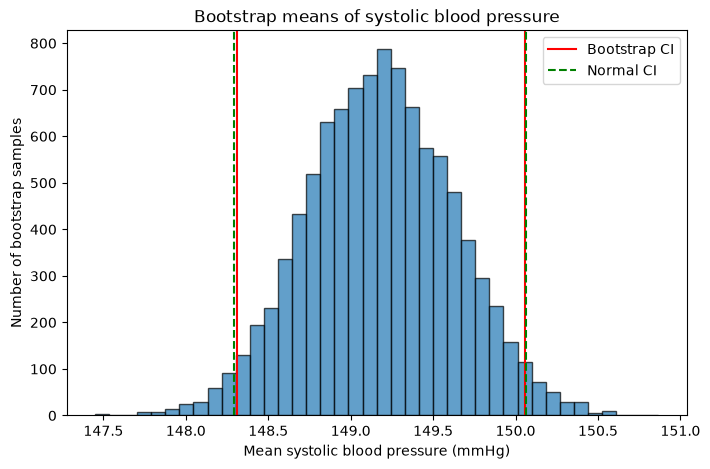

In [14]:
fig, ax = plt.subplots(figsize=(8, 5))
ax.hist(boot_means, bins=40, edgecolor="black", alpha=0.7)

# Red lines = bootstrap CI, green dashed lines = normal CI
ax.axvline(boot_low, color="red", label="Bootstrap CI")
ax.axvline(boot_high, color="red")
ax.axvline(ci_low, color="green", linestyle="--", label="Normal CI")
ax.axvline(ci_high, color="green", linestyle="--")

ax.set_title("Bootstrap means of systolic blood pressure")
ax.set_xlabel("Mean systolic blood pressure (mmHg)")
ax.set_ylabel("Number of bootstrap samples")
ax.legend()
plt.show()

### 6.3 Comparison of the two methods

| Method | 95% CI (mmHg) | Width |
|---|---|---|
| Normal approximation | 148.29 – 150.07 | 1.77 |
| Bootstrap | 148.31 – 150.06 | 1.75 |

The two methods give almost the same result. This is expected,
because the sample is large and the data looks close to normal
(see the histogram in 4.1). Then the Central Limit Theorem works well.

- **Normal approximation** is fast and simple, but it assumes that
  the mean is normally distributed.
- **Bootstrap** needs no such assumption and works also for small
  or skewed data, but it takes longer to run and the result changes
  a little with the random seed.

In this case both methods are good. If the data had been small or
very skewed, I would trust the bootstrap more.

## 7. Hypothesis test: smokers vs non-smokers
I test the hypothesis "Smokers have higher mean blood pressure than non-smokers".

- H0: The mean blood pressure of smokers is not higher than for non-smokers.
- H1: The mean blood pressure of smokers is higher than for non-smokers.

This is a one-sided test, because the hypothesis says "higher".
I use the significance level α = 0.05.

In [15]:
# Split blood pressure into two groups
smokers = df[df["smoker"] == "Yes"]["systolic_bp"]
non_smokers = df[df["smoker"] == "No"]["systolic_bp"]

observed_diff = smokers.mean() - non_smokers.mean()

print(f"Smokers:     n = {len(smokers)}, mean = {smokers.mean():.2f} mmHg")
print(f"Non-smokers: n = {len(non_smokers)}, mean = {non_smokers.mean():.2f} mmHg")
print(f"Difference:  {observed_diff:.2f} mmHg")

Smokers:     n = 213, mean = 149.52 mmHg
Non-smokers: n = 587, mean = 149.05 mmHg
Difference:  0.47 mmHg


In [16]:
def t_statistic(group_a, group_b):
    """Welch t-statistic for the difference in means (group_a - group_b)."""
    diff = np.mean(group_a) - np.mean(group_b)
    # ddof=1 divides by n-1, so pandas and numpy give the same result
    se = np.sqrt(np.var(group_a, ddof=1) / len(group_a) + np.var(group_b, ddof=1) / len(group_b))
    return diff / se


t_value = t_statistic(smokers, non_smokers)
print(f"t = {t_value:.2f}")

# One-sided test with α = 0.05, the critical value is 1.645
if t_value > 1.645:
    print("Reject H0")
else:
    print("Cannot reject H0")

t = 0.45
Cannot reject H0


### 7.1 Permutation test
As a second method I use a permutation test. If H0 is true, the labels
"smoker" and "non-smoker" do not matter. I shuffle the labels 10,000 times
and count how often the difference is as large as the observed one.
This share is the p-value. The method does not need the assumption of
normal distribution.

In [17]:
def permutation_test(group_a, group_b, n_perm=10000):
    """One-sided permutation test. Returns the p-value for mean(a) > mean(b)."""
    observed = group_a.mean() - group_b.mean()
    all_values = np.concatenate([group_a, group_b])
    n_a = len(group_a)

    count = 0
    for _ in range(n_perm):
        # Shuffle all values and split into two new groups with the same sizes
        shuffled = np.random.permutation(all_values)
        # First n_a values = new "smokers", the rest = new "non-smokers"
        diff = shuffled[:n_a].mean() - shuffled[n_a:].mean()
        # Count the rounds where the difference is as large as the real one, or larger
        if diff >= observed:
            count += 1

    return count / n_perm


p_value = permutation_test(smokers, non_smokers)
print(f"p-value (permutation): {p_value:.4f}")

p-value (permutation): 0.3218


### 7.2 Result
| Method | Result | Decision (α = 0.05) |
|---|---|---|
| Welch t-test | t = 0.45 (critical value 1.645) | Cannot reject H0 |
| Permutation test | p = 0.32 | Cannot reject H0 |

Smokers have a mean blood pressure that is only 0.47 mmHg higher than
non-smokers. Both methods show that such a small difference can easily happen
by chance. In the permutation test, a difference this large or larger
happened in about 32% of the shuffles. Therefore I **cannot reject H0**.

This does not prove that smoking has no effect on blood pressure.
It only means that this data does not give enough evidence for the
hypothesis. In the next section I check how good the test is at
finding a difference when there really is one (power).

## 8. Power simulation
My test did not find a difference. But maybe the test is just not
strong enough? To check this, I make fake data where I know there
is a real difference of 3 mmHg. The groups have the same size and
spread as the real data. I run the t-test 1000 times and count how
often it finds the difference. This is the power of the test.
Usually 80% or more is good enough.

In [18]:
def simulate_power(true_diff, n_a, n_b, sd, n_sim=1000):
    """Returns how often the t-test finds a difference when the true difference is true_diff."""
    rejections = 0
    for _ in range(n_sim):
        # Fake data: group a is true_diff higher than group b
        # Mean 0 is fine, because the t-test only looks at the difference.
        fake_a = np.random.normal(loc=true_diff, scale=sd, size=n_a)
        fake_b = np.random.normal(loc=0, scale=sd, size=n_b)
        # If t is above 1.645, the test found the difference
        if t_statistic(fake_a, fake_b) > 1.645:
            rejections += 1

    return rejections / n_sim


# Same sd and group sizes as the real data
sd = df["systolic_bp"].std()
power_3 = simulate_power(3, len(smokers), len(non_smokers), sd)
print(f"Power if the true difference is 3 mmHg: {power_3:.1%}")

# How often does the test find a difference as small as the one in the data?
power_obs = simulate_power(observed_diff, len(smokers), len(non_smokers), sd)
print(f"Power if the true difference is {observed_diff:.2f} mmHg: {power_obs:.1%}")

Power if the true difference is 3 mmHg: 88.4%
Power if the true difference is 0.47 mmHg: 10.7%


**Comment:** If smokers really had 3 mmHg higher blood pressure,
the test would find it about 88% of the time. So the test works
well for a difference of that size.

But the difference in my data was only 0.47 mmHg. With a true
difference that small, the test finds it only about 11% of the time.
So the result in section 7 does not mean that smoking has no effect.
It only means that if there is an effect, it is probably small,
and a bigger study would be needed to find it.

## 9. Method choices
| Part | Method | Why I chose it |
|---|---|---|
| Reproducibility | Random seed 42, relative path | Same results every time, and the notebook runs on any computer [5] |
| Unusual values | BMI | Weight alone is not enough, it depends on height [1] |
| High blood pressure | Limit 140 mmHg | Common limit for high blood pressure [4] |
| Graphs | Histogram, boxplot, bar chart | Histogram shows the spread, boxplot compares groups, bar chart shows shares [5] |
| Simulation | `np.random.binomial` | Disease is 0/1, so each person is like a coin flip with p = 5.88% [2] [3] |
| CI 1 | Normal approximation | Simple and fast, works well when n is large (n = 800) [3] [5] |
| CI 2 | Bootstrap | Does not need a normal distribution, good for comparison [5] |
| Test 1 | Welch t-test | Does not assume equal variances, which is safer when the groups have very different sizes (213 vs 587) [3] [5] |
| Test 2 | Permutation test | Does not need a normal distribution, easy to understand [2] |
| Power | Simulation with fake data | Shows how often the test finds a real difference [5] |

## 10. Conclusion
- **Data:** 800 participants, no missing values or duplicates.
  23 people have a very low BMI (under 16), but I kept them because
  I cannot prove that they are errors.
- **Blood pressure:** The mean is 149 mmHg, and 76.9% are above
  140 mmHg. High blood pressure is common in this group.
- **Disease:** 5.88% have the disease. The simulation gave 5.60%,
  which is normal random variation (95% of simulations: 4.5–7.4%).
- **Confidence interval:** The true mean blood pressure is probably
  between about 148.3 and 150.1 mmHg. Both methods agree.
- **Smoking:** Smokers have only 0.47 mmHg higher blood pressure.
  This is not significant (p = 0.32). The power simulation shows that
  the test finds a difference of 3 mmHg in 88% of the cases, but a
  difference of 0.47 mmHg in only 11%.

**In short:** High blood pressure is common in the whole group, not
only among smokers. If smoking affects blood pressure, the effect is
small. Other factors, for example age, may be more important. This can
be studied in Part 2.

## 11. References
1. World Health Organization – Nutrition Landscape Information System:
   Malnutrition in women (BMI cut-off values):
   https://www.who.int/data/nutrition/nlis/info/malnutrition-in-women
2. NumPy documentation – `numpy.random.binomial` and `numpy.random.permutation`:
   https://numpy.org/doc/stable/reference/random/generated/numpy.random.binomial.html
   https://numpy.org/doc/stable/reference/random/generated/numpy.random.permutation.html
3. Nield, T. (2022). *Essential Math for Data Science.* O'Reilly Media.
   Chapter 2 (binomial distribution) and Chapter 3 (descriptive and
   inferential statistics, the normal distribution, hypothesis testing).
4. World Health Organization – Hypertension fact sheet (140 mmHg limit):
   https://www.who.int/news-room/fact-sheets/detail/hypertension
5. EC Utbildning, Pythonprogrammering och statistisk dataanalys course material (lessons and videos):
   - 2.4 Reproducerbarhet (random seed, requirements.txt, relative paths)
   - 4.1 Deskriptiv statistik (mean, median, min, max)
   - 5.2 Välj rätt figur (histogram, boxplot, bar chart)
   - 6.1 Sampling och variation (sampling variation, standard error)
   - 6.2 Konfidensintervall (normal approximation and bootstrap)
   - 6.3 Hypotesprövning (H0, H1, p-value)
   - 7.4 Power och flerfaldig testning (power)